# 1. Transformada Discreta de Fourier (DFT) e Inversa (IDFT) via Matriz Explícita

Nesta seção, implementamos a DFT e a IDFT em sua forma matricial arcaica. 

A matriz de transformação de Fourier $W$ de dimensão $N \times N$ possui elementos definidos por:
$$W_{k,n} = e^{-j \frac{2\pi}{N} k n} = \cos\left(\frac{2\pi k n}{N}\right) - j \cdot \sin\left(\frac{2\pi k n}{N}\right)$$

A transformação completa é computada pela multiplicação matricial elemento a elemento:
$$X = W \cdot x \implies X[k] = \sum_{n=0}^{N-1} W_{k,n} \cdot x[n]$$

Para a IDFT, utiliza-se a matriz conjugada $W^{-1}$ escalada por $\frac{1}{N}$:
$$x = \frac{1}{N} W^* \cdot X \implies x[n] = \frac{1}{N} \sum_{k=0}^{N-1} W^*_{n,k} \cdot X[k]$$

=== ESPECTRO DFT INICIAL X[k] (Retangular | Polar) ===
[ 0]    4.000 +   0.000j  |  Mag:   4.000  Fase:     0.0°
[ 1]    0.000 -   2.000j  |  Mag:   2.000  Fase:   -90.0°
[ 2]    0.000 +   0.000j  |  Mag:   0.000  Fase:     0.0°
[ 3]   -0.000 +   2.000j  |  Mag:   2.000  Fase:    90.0°


<>:96: SyntaxWarning: invalid escape sequence '\p'
<>:96: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_9872/1797738762.py:96: SyntaxWarning: invalid escape sequence '\p'
  ax2.set_title('1B. Espectro de Fase $\phi[k]$ (DFT)', fontweight='bold')


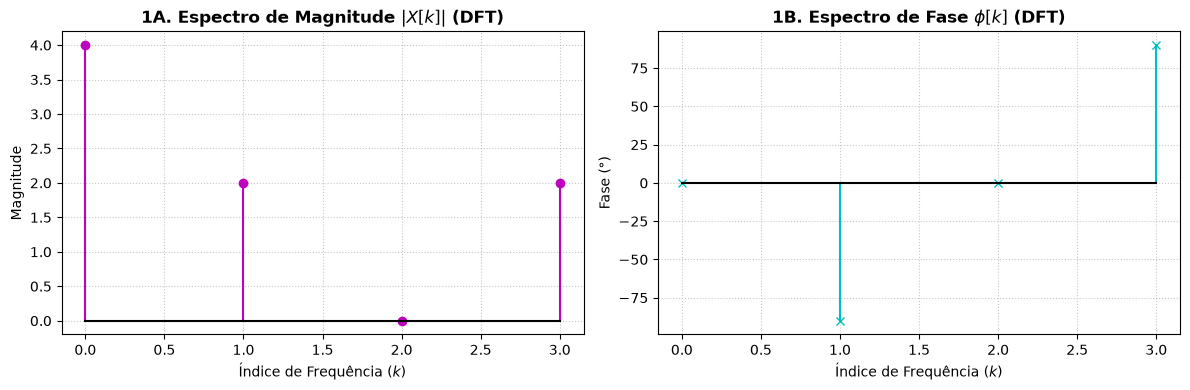

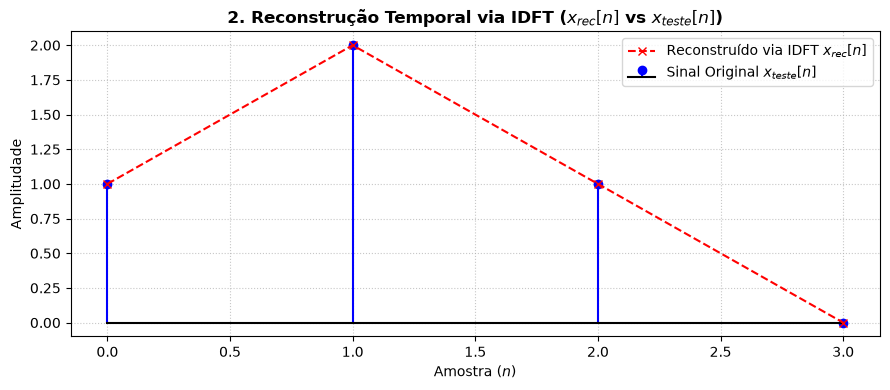

In [16]:
import numpy as np
import math
import matplotlib.pyplot as plt
import time

def dft_imp(x):
    """
    Calcula a DFT construindo a matriz de Fourier W explicitamente
    e multiplicando-a pelo vetor x via laços de repetição manuais.
    """
    N = len(x)
    
    # 1. Construcao manual da Matriz W de Fourier (N x N)
    W = np.zeros((N, N), dtype=complex)
    for k in range(N):
        for n in range(N):
            angulo = -2 * math.pi * k * n / N
            # Formula de Euler: e^(j*theta) = cos(theta) + j*sin(theta)
            real = math.cos(angulo)
            imag = math.sin(angulo)
            W[k, n] = complex(real, imag)
    
    # 2. Multiplicacao Matriz-Vetor manual (X = W * x)
    X = np.zeros(N, dtype=complex)
    for k in range(N):          # Iteracao sobre as linhas de W (frequencias)
        soma_acumulada = complex(0.0, 0.0)
        for n in range(N):      # Iteracao sobre as colunas de W (tempo)
            soma_acumulada += W[k, n] * x[n]
        X[k] = soma_acumulada
        
    return X

def idft_imp(X):
    """
    Calcula a IDFT construindo a matriz conjugada W_inv
    e multiplicando-a pelo vetor X via laços de repetição manuais.
    """
    N = len(X)
    
    # 1. Construcao manual da Matriz Inversa W_inv (N x N)
    W_inv = np.zeros((N, N), dtype=complex)
    for n in range(N):
        for k in range(N):
            angulo = 2 * math.pi * k * n / N
            real = math.cos(angulo)
            imag = math.sin(angulo)
            W_inv[n, k] = complex(real, imag)
    
    # 2. Multiplicacao Matriz-Vetor manual (x = (1/N) * W_inv * X)
    x = np.zeros(N, dtype=complex)
    for n in range(N):          # Iteracao sobre as linhas de W_inv (tempo)
        soma_acumulada = complex(0.0, 0.0)
        for k in range(N):      # Iteracao sobre as colunas de W_inv (frequencias)
            soma_acumulada += W_inv[n, k] * X[k]
        x[n] = soma_acumulada / N
        
    return x

def formatar_complexo(val, prec=3):
    """Formata vetor complexo para exibições Retangular (a + bj) e Polar (|X| ∠ θ°)."""
    linhas = []
    for i, c in enumerate(val):
        mag = abs(c)
        fase_deg = math.degrees(math.atan2(c.imag, c.real))
        sinal = "+" if c.imag >= 0 else "-"
        linhas.append(f"[{i:2d}] {c.real:8.{prec}f} {sinal} {abs(c.imag):7.{prec}f}j  |  Mag: {mag:7.{prec}f}  Fase: {fase_deg:7.1f}°")
    return "\n".join(linhas)

# --- Sinal Inicial de Teste ---
x_teste = np.array([1,2,1,0], dtype=float)

# 1. IDA: Cálculo da DFT
X_dft_teste = dft_imp(x_teste)

# 2. VOLTA: Cálculo da IDFT
x_recuperado_teste = idft_imp(X_dft_teste).real

print("=== ESPECTRO DFT INICIAL X[k] (Retangular | Polar) ===")
print(formatar_complexo(X_dft_teste))

# ==============================================================================
# GRAFICO 1: A IDA (DFT) - Resposta em Frequência (Magnitude e Fase Separadas)
# ==============================================================================
fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
eixo_k = np.arange(len(x_teste))

# Subplot 1A: Magnitude
ax1.stem(eixo_k, np.abs(X_dft_teste), linefmt='m-', markerfmt='mo', basefmt='k-')
ax1.set_title('1A. Espectro de Magnitude $|X[k]|$ (DFT)', fontweight='bold')
ax1.set_xlabel('Índice de Frequência ($k$)')
ax1.set_ylabel('Magnitude')
ax1.grid(True, ls=':', alpha=0.7)

# Subplot 1B: Fase em Graus
ax2.stem(eixo_k, np.angle(X_dft_teste, deg=True), linefmt='c-', markerfmt='cx', basefmt='k-')
ax2.set_title('1B. Espectro de Fase $\phi[k]$ (DFT)', fontweight='bold')
ax2.set_xlabel('Índice de Frequência ($k$)')
ax2.set_ylabel('Fase (°)')
ax2.grid(True, ls=':', alpha=0.7)

plt.tight_layout()
plt.show()

# ==============================================================================
# GRAFICO 2: A VOLTA (IDFT) - Reconstrução do Sinal no Domínio do Tempo
# ==============================================================================
plt.figure(figsize=(9, 4))
plt.stem(range(len(x_teste)), x_teste, linefmt='b-', markerfmt='bo', basefmt='k-', label='Sinal Original $x_{teste}[n]$')
plt.plot(range(len(x_recuperado_teste)), x_recuperado_teste, 'r--x', label='Reconstruído via IDFT $x_{rec}[n]$', linewidth=1.5)
plt.title('2. Reconstrução Temporal via IDFT ($x_{rec}[n]$ vs $x_{teste}[n]$)', fontweight='bold')
plt.xlabel('Amostra ($n$)')
plt.ylabel('Amplitudade')
plt.grid(True, ls=':', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

# 4.2 Validação Experimental das Propriedades da DFT

A validação experimental do algoritmo matricial foi realizada verificando as propriedades fundamentais da Transformada Discreta de Fourier ($\text{DFT}$) que regem as relações entre o domínio do tempo e da frequência[cite: 1, 2]:

1. **Linearidade:**[cite: 1, 2]
   $$\mathcal{F}\{\alpha \cdot x_1[n] + \beta \cdot x_2[n]\} = \alpha \cdot X_1[k] + \beta \cdot X_2[k]$$

2. **Deslocamento Temporal (Circular):**[cite: 1, 2]
   $$\mathcal{F}\{x[(n - n_0) \bmod N]\} = X[k] \cdot e^{-j \frac{2\pi}{N} k n_0}$$

3. **Deslocamento na Frequência (Modulação):**[cite: 2]
   $$\mathcal{F}\left\{x[n] \cdot e^{j \frac{2\pi}{N} k_0 n}\right\} = X[(k - k_0) \bmod N]$$

4. **Reversão Temporal:**[cite: 2]
   $$\mathcal{F}\{x[(-n) \bmod N]\} = X[(-k) \bmod N]$$

5. **Conjugação Complexa:**[cite: 2]
   $$\mathcal{F}\{x^*[n]\} = X^*[(-k) \bmod N]$$

6. **Simetria Conjugada (para $x[n]$ real):**[cite: 1, 2]
   $$X[k] = X^*[(N - k) \bmod N]$$

7. **Convolução Circular no Tempo:**[cite: 2]
   $$\mathcal{F}\{(x_1 \circledast x_2)[n]\} = X_1[k] \cdot X_2[k]$$

8. **Multiplicação Ponto a Ponto (Tempo):**[cite: 2]
   $$\mathcal{F}\{x_1[n] \cdot x_2[n]\} = \frac{1}{N} (X_1 \circledast X_2)[k]$$

9. **Teorema de Parseval (Conservação de Energia):**[cite: 1, 2]
   $$\sum_{n=0}^{N-1} x_1[n] \cdot x_2^*[n] = \frac{1}{N} \sum_{k=0}^{N-1} X_1[k] \cdot X_2^*[k]$$
   $$\text{Para o mesmo sinal: } \sum_{n=0}^{N-1} |x[n]|^2 = \frac{1}{N} \sum_{k=0}^{N-1} |X[k]|^2$$

10. **Periodicidade:**[cite: 2]
    $$X[k + N] = X[k]$$

11. **Amostragem na Frequência (Zero-Padding):**[cite: 2]
    $$\text{O preenchimento com zeros ($N > L$) resulta na interpolação do espectro } X[k] \text{ em } N \text{ pontos.}$$

In [1]:
import numpy as np

# Definição da função DFT matricial
def dft_imp(x):
    N = len(x)
    n = np.arange(N)
    k = n.reshape((N, 1))
    W = np.exp(-1j * 2 * np.pi * k * n / N)
    return np.dot(W, x)

# Configuração do experimento
np.random.seed(42)
N = 16

# Sinal real para testes gerais
x1 = np.random.randn(N)
x2 = np.random.randn(N)

# Sinal complexo para teste de conjugação
x_comp = np.random.randn(N) + 1j * np.random.randn(N)

# DFTs base
X1 = dft_imp(x1)
X2 = dft_imp(x2)
X_comp = dft_imp(x_comp)

print("=== VALIDAÇÃO EXPERIMENTAL DAS PROPRIEDADES DA DFT ===")

# 1. Linearidade
a, b = 2.5, -1.5
lhs_lin = dft_imp(a * x1 + b * x2)
rhs_lin = a * X1 + b * X2
erro_lin = np.max(np.abs(lhs_lin - rhs_lin))
print(f"1. Linearidade - Erro Máximo: {erro_lin:.2e}")

# 2. Deslocamento Temporal (Circular)
n0 = 3
x1_shift = np.roll(x1, n0)
k_indices = np.arange(N)
fator_fase_tempo = np.exp(-1j * 2 * np.pi * k_indices * n0 / N)
X1_shift_teorico = X1 * fator_fase_tempo
X1_shift_pratico = dft_imp(x1_shift)
erro_shift_tempo = np.max(np.abs(X1_shift_pratico - X1_shift_teorico))
print(f"2. Deslocamento Temporal - Erro Máximo: {erro_shift_tempo:.2e}")

# 3. Deslocamento na Frequência (Modulação)
k0 = 2
modulacao = np.exp(1j * 2 * np.pi * k0 * np.arange(N) / N)
x1_mod = x1 * modulacao
X1_mod_pratico = dft_imp(x1_mod)
X1_shift_freq_teorico = np.roll(X1, k0)
erro_shift_freq = np.max(np.abs(X1_mod_pratico - X1_shift_freq_teorico))
print(f"3. Deslocamento na Frequência - Erro Máximo: {erro_shift_freq:.2e}")

# 4. Reversão Temporal
x1_rev = np.roll(x1[::-1], 1)  # x[(-n) mod N]
X1_rev_pratico = dft_imp(x1_rev)
X1_rev_teorico = np.roll(X1[::-1], 1)  # X[(-k) mod N]
erro_reversao = np.max(np.abs(X1_rev_pratico - X1_rev_teorico))
print(f"4. Reversão Temporal - Erro Máximo: {erro_reversao:.2e}")

# 5. Conjugação Complexa
x_comp_conj = np.conj(x_comp)
X_comp_conj_pratico = dft_imp(x_comp_conj)
X_comp_conj_teorico = np.roll(np.conj(X_comp)[::-1], 1)
erro_conjugacao = np.max(np.abs(X_comp_conj_pratico - X_comp_conj_teorico))
print(f"5. Conjugação Complexa - Erro Máximo: {erro_conjugacao:.2e}")

# 6. Simetria Conjugada (para sinal real x1)
X1_conj_espelhado = np.conj(np.roll(X1[::-1], 1))
erro_simetria = np.max(np.abs(X1 - X1_conj_espelhado))
print(f"6. Simetria Conjugada (Sinal Real) - Erro Máximo: {erro_simetria:.2e}")

# 7. Convolução Circular no Tempo
y_conv_circ = np.zeros(N, dtype=np.complex128)
for n_idx in range(N):
    y_conv_circ[n_idx] = np.sum(x1 * np.roll(x2[::-1], n_idx + 1))
Y_conv_pratico = dft_imp(y_conv_circ)
Y_conv_teorico = X1 * X2
erro_conv_circ = np.max(np.abs(Y_conv_pratico - Y_conv_teorico))
print(f"7. Convolução Circular no Tempo - Erro Máximo: {erro_conv_circ:.2e}")

# 8. Multiplicação Ponto a Ponto no Tempo
x_mult = x1 * x2
X_mult_pratico = dft_imp(x_mult)
X_conv_freq = np.zeros(N, dtype=np.complex128)
for k_idx in range(N):
    X_conv_freq[k_idx] = np.sum(X1 * np.roll(X2[::-1], k_idx + 1))
X_mult_teorico = (1.0 / N) * X_conv_freq
erro_mult_tempo = np.max(np.abs(X_mult_pratico - X_mult_teorico))
print(f"8. Multiplicação Ponto a Ponto - Erro Máximo: {erro_mult_tempo:.2e}")

# 9. Teorema de Parseval
energia_tempo = np.sum(np.abs(x1)**2)
energia_freq = (1 / N) * np.sum(np.abs(X1)**2)
erro_parseval = np.abs(energia_tempo - energia_freq)
print(f"9. Teorema de Parseval - Erro Absoluto: {erro_parseval:.2e}")

# 10. Periodicidade
W_ext = np.exp(-1j * 2 * np.pi * (k_indices + N).reshape((N, 1)) * np.arange(N) / N)
X1_periodico = np.dot(W_ext, x1)
erro_periodicidade = np.max(np.abs(X1 - X1_periodico))
print(f"10. Periodicidade na Frequência - Erro Máximo: {erro_periodicidade:.2e}")

=== VALIDAÇÃO EXPERIMENTAL DAS PROPRIEDADES DA DFT ===
1. Linearidade - Erro Máximo: 3.55e-15
2. Deslocamento Temporal - Erro Máximo: 6.31e-14
3. Deslocamento na Frequência - Erro Máximo: 5.81e-14
4. Reversão Temporal - Erro Máximo: 5.41e-14
5. Conjugação Complexa - Erro Máximo: 5.15e-14
6. Simetria Conjugada (Sinal Real) - Erro Máximo: 5.49e-14
7. Convolução Circular no Tempo - Erro Máximo: 1.38e-13
8. Multiplicação Ponto a Ponto - Erro Máximo: 3.13e-14
9. Teorema de Parseval - Erro Absoluto: 8.88e-15
10. Periodicidade na Frequência - Erro Máximo: 5.32e-14
